# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [3]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [4]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <ArrowStringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country/countries **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country/countries and its story

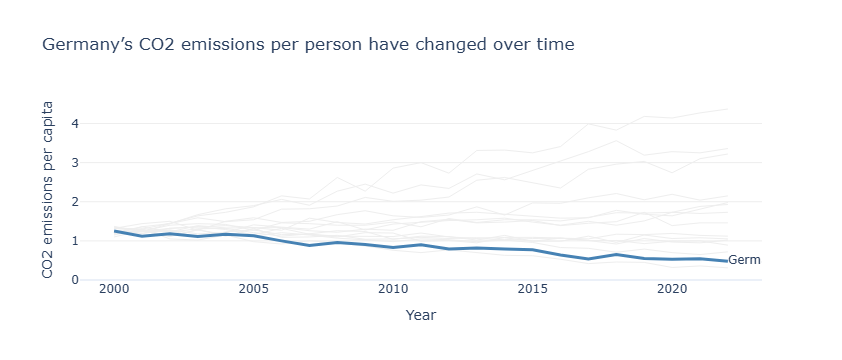

In [5]:
# Task 1 
# YOUR CODE HERE


# CO2 emissions per person across countries

fig1 = go.Figure()

for country in df['Country'].unique():
    country_data = df[df['Country'] == country].sort_values('Year')

    fig1.add_trace(go.Scatter(
        x=country_data['Year'],
        y=country_data['CO2_per_capita'],
        mode='lines',
        line=dict(color='#EEEEEE', width=1),
        showlegend=False,
        hovertemplate=country + '<br>Year: %{x}<br>CO2 per capita: %{y}<extra></extra>'
    ))

# Highlight Germany
germany = df[df['Country'] == 'Germany'].sort_values('Year')

fig1.add_trace(go.Scatter(
    x=germany['Year'],
    y=germany['CO2_per_capita'],
    mode='lines+text',
    line=dict(color='steelblue', width=3),
    text=[''] * (len(germany) - 1) + ['Germany'],
    textposition='middle right',
    showlegend=False
))

fig1.update_layout(
    title='Germany’s CO2 emissions per person have changed over time',
    xaxis_title='Year',
    yaxis_title='CO2 emissions per capita',
    template='plotly_white'
)

fig1.update_xaxes(showgrid=False)
fig1.update_yaxes(rangemode='tozero', gridcolor='#EEEEEE')

fig1.show()


---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

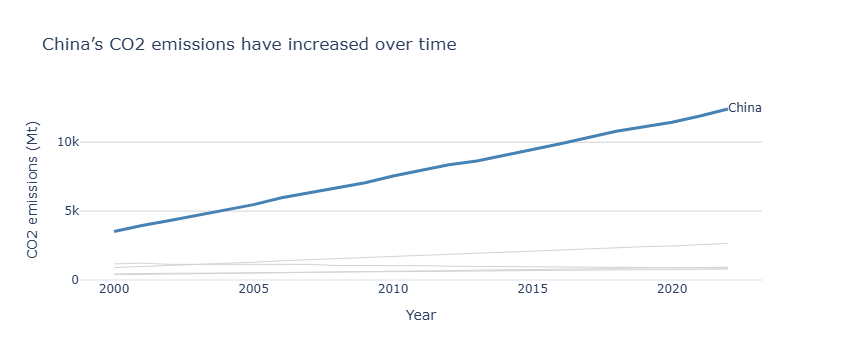

In [6]:
# Task 2 
# YOUR CODE HERE

# CO2 emissions in Asian countries

asia = df[df['Region'].str.contains('Asia', case=False, na=False)]

fig2 = go.Figure()

for country in asia['Country'].unique():
    country_data = asia[asia['Country'] == country].sort_values('Year')

    fig2.add_trace(go.Scatter(
        x=country_data['Year'],
        y=country_data['CO2_Mt'],
        mode='lines',
        line=dict(color='lightgrey', width=1),
        showlegend=False
    ))

# Highlight China
china = asia[asia['Country'] == 'China'].sort_values('Year')

fig2.add_trace(go.Scatter(
    x=china['Year'],
    y=china['CO2_Mt'],
    mode='lines+text',
    line=dict(color='steelblue', width=3),
    text=[''] * (len(china) - 1) + ['China'],
    textposition='middle right',
    showlegend=False
))

fig2.update_layout(
    title='China’s CO2 emissions have increased over time',
    xaxis_title='Year',
    yaxis_title='CO2 emissions (Mt)',
    template='plotly_white'
)

fig2.update_xaxes(showgrid=False)
fig2.update_yaxes(rangemode='tozero', gridcolor='lightgrey')

fig2.show()

